<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook2_EDA_and_Hypotheses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick student-mat.csv

Saving student-mat.csv to student-mat.csv


{'student-mat.csv': b'school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3\n"GP";"F";18;"U";"GT3";"A";4;4;"at_home";"teacher";"course";"mother";2;2;0;"yes";"no";"no";"no";"yes";"yes";"no";"no";4;3;4;1;1;3;6;"5";"6";6\n"GP";"F";17;"U";"GT3";"T";1;1;"at_home";"other";"course";"father";1;2;0;"no";"yes";"no";"no";"no";"yes";"yes";"no";5;3;3;1;1;3;4;"5";"5";6\n"GP";"F";15;"U";"LE3";"T";1;1;"at_home";"other";"other";"mother";1;2;3;"yes";"no";"yes";"no";"yes";"yes";"yes";"no";4;3;2;2;3;3;10;"7";"8";10\n"GP";"F";15;"U";"GT3";"T";4;2;"health";"services";"home";"mother";1;3;0;"no";"yes";"yes";"yes";"yes";"yes";"yes";"yes";3;2;2;1;1;5;2;"15";"14";15\n"GP";"F";16;"U";"GT3";"T";3;3;"other";"other";"home";"father";1;2;0;"no";"yes";"yes";"no";"yes";"yes";"no";"no";4;3;2;1;2;5;4;"6";"10";10\n"GP";"M";16;"U";"LE3";"T";4;3;"service

In [2]:
# Cell 1: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
df = pd.read_csv("student-mat.csv", sep=";")
df["passed"] = (df["G3"] >= 10).astype(int)

groups = {
    "Study habits": ["studytime", "failures", "absences", "paid", "schoolsup", "higher"],
    "Family background": ["Medu", "Fedu", "famsup", "famrel", "Pstatus", "famsize"],
    "Lifestyle": ["goout", "freetime", "Dalc", "Walc", "romantic", "internet", "health"],
}
print("Groups defined:", {k: len(v) for k, v in groups.items()})

Groups defined: {'Study habits': 6, 'Family background': 6, 'Lifestyle': 7}


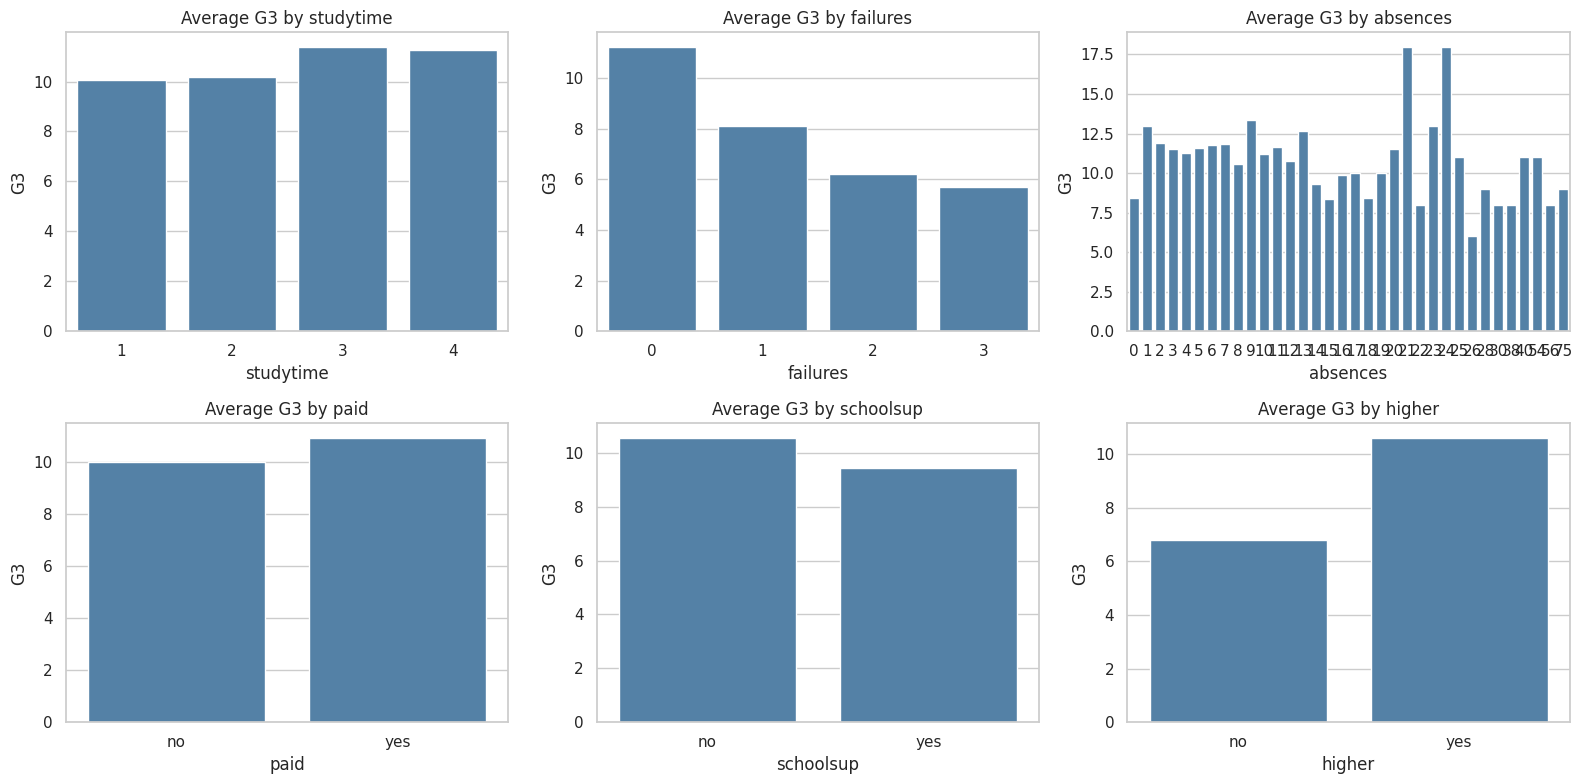

In [3]:
# Cell 2: study habits, average G3 and pass rate
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, groups["Study habits"]):
    order = sorted(df[c].unique())
    sns.barplot(x=c, y="G3", data=df, order=order, errorbar=None, ax=ax, color="steelblue")
    ax.set_title(f"Average G3 by {c}")
plt.tight_layout()
plt.savefig("eda_study_habits.png", dpi=150, bbox_inches="tight")
plt.show()

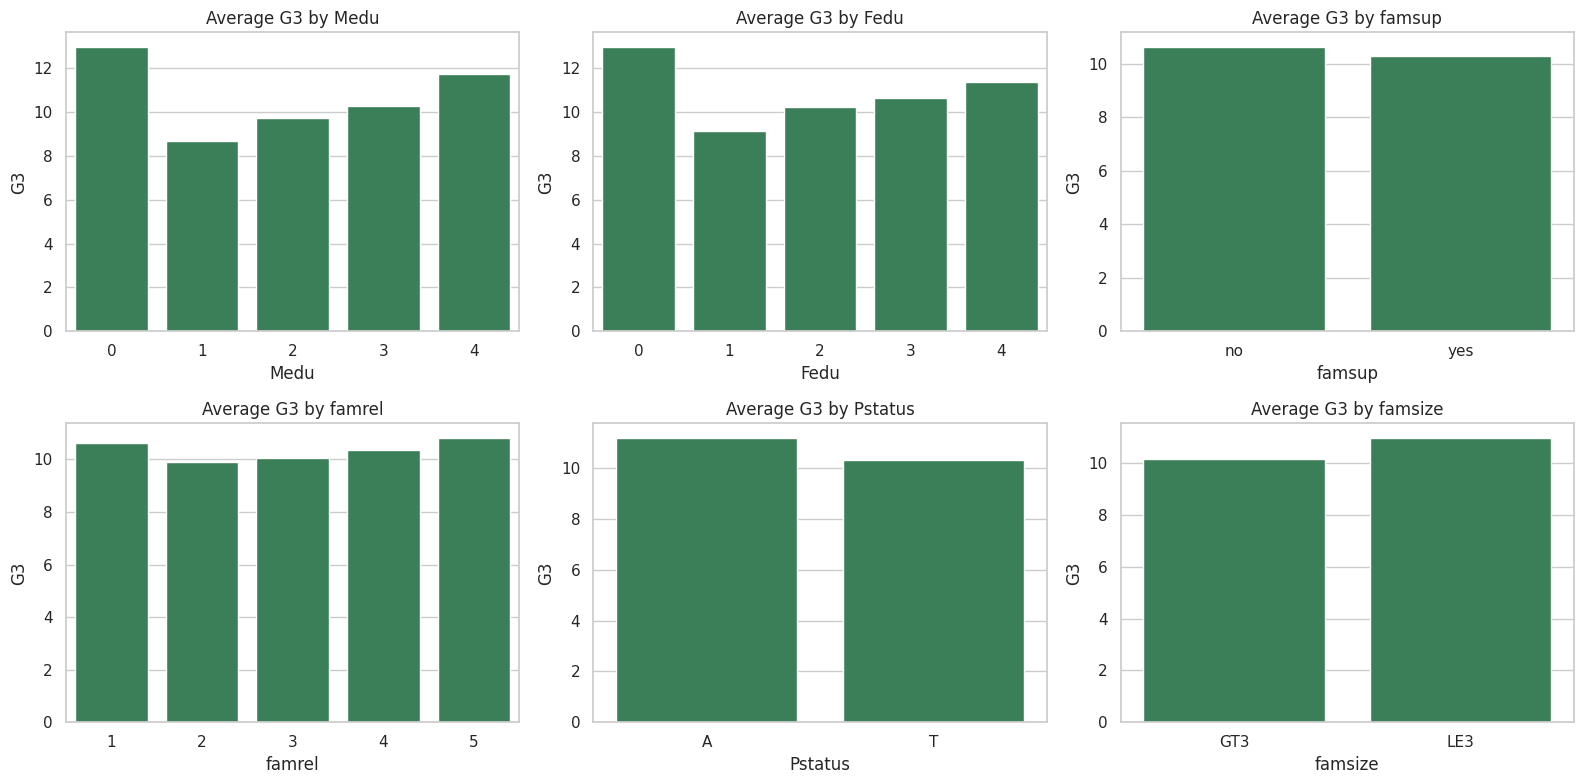

In [4]:
# Cell 3: family background
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, groups["Family background"]):
    order = sorted(df[c].unique())
    sns.barplot(x=c, y="G3", data=df, order=order, errorbar=None, ax=ax, color="seagreen")
    ax.set_title(f"Average G3 by {c}")
plt.tight_layout()
plt.savefig("eda_family.png", dpi=150, bbox_inches="tight")
plt.show()

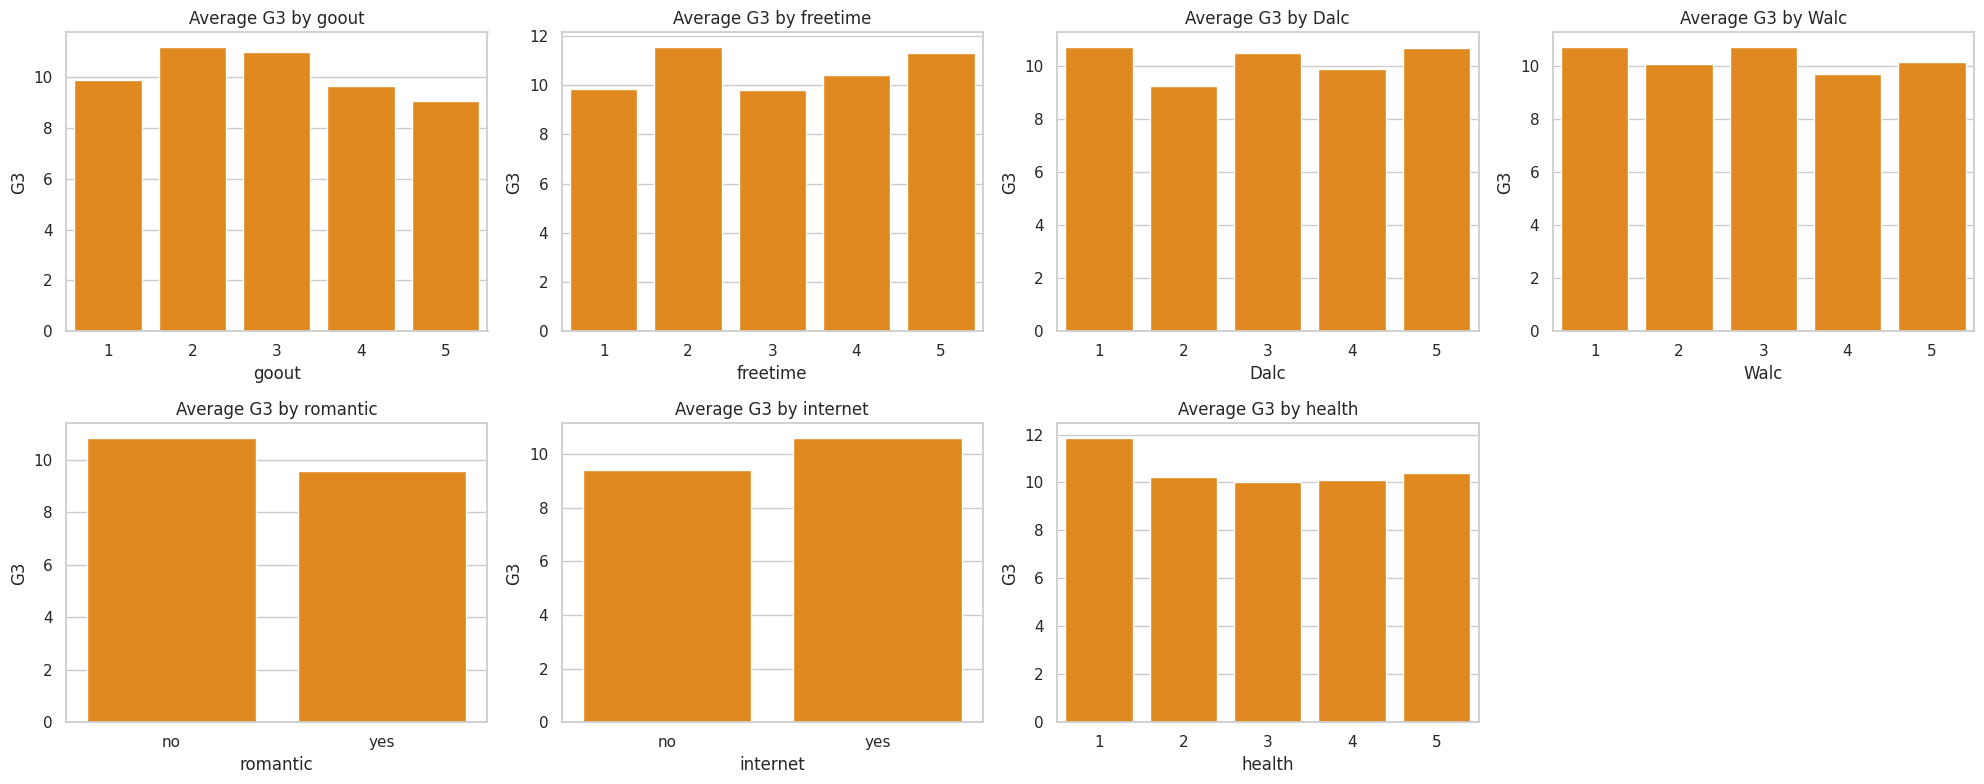

In [5]:
# Cell 4: lifestyle
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.flat, groups["Lifestyle"]):
    order = sorted(df[c].unique())
    sns.barplot(x=c, y="G3", data=df, order=order, errorbar=None, ax=ax, color="darkorange")
    ax.set_title(f"Average G3 by {c}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("eda_lifestyle.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Cell 5: a reusable hypothesis-testing function
def compare(df, col, group_a, group_b, target="G3"):
    a = df[df[col] == group_a][target]
    b = df[df[col] == group_b][target]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    return {
        "feature": col,
        "group A": f"{group_a} (n={len(a)})",
        "group B": f"{group_b} (n={len(b)})",
        "mean A": round(a.mean(), 2),
        "mean B": round(b.mean(), 2),
        "difference": round(a.mean() - b.mean(), 2),
        "p-value": round(p, 4),
        "significant": "Yes" if p < 0.05 else "No",
    }

tests = [
    compare(df, "higher", "yes", "no"),
    compare(df, "internet", "yes", "no"),
    compare(df, "romantic", "yes", "no"),
    compare(df, "address", "U", "R"),
    compare(df, "paid", "yes", "no"),
    compare(df, "schoolsup", "yes", "no"),
    compare(df, "sex", "M", "F"),
    compare(df, "famsup", "yes", "no"),
]
results = pd.DataFrame(tests)
results

,feature,group A,group B,mean A,mean B,difference,p-value,significant
0,higher,yes (n=375),no (n=20),10.61,6.80,3.81,0.0024,Yes
1,internet,yes (n=329),no (n=66),10.62,9.41,1.21,0.0496,Yes
2,romantic,yes (n=132),no (n=263),9.58,10.84,-1.26,0.0127,Yes
3,address,U (n=307),R (n=88),10.67,9.51,1.16,0.0366,Yes
4,paid,yes (n=181),no (n=214),10.92,9.99,0.94,0.0379,Yes
5,schoolsup,yes (n=51),no (n=344),9.43,10.56,-1.13,0.0197,Yes
6,sex,M (n=187),F (n=208),10.91,9.97,0.95,0.0396,Yes
7,famsup,yes (n=242),no (n=153),10.27,10.64,-0.37,0.4398,No


In [7]:
# Cell 6: repeat the tests without the zero-grade students
df_nz = df[df["G3"] > 0]
print("Students kept:", len(df_nz), "of", len(df))

tests_nz = [
    compare(df_nz, "higher", "yes", "no"),
    compare(df_nz, "internet", "yes", "no"),
    compare(df_nz, "romantic", "yes", "no"),
    compare(df_nz, "address", "U", "R"),
    compare(df_nz, "paid", "yes", "no"),
    compare(df_nz, "schoolsup", "yes", "no"),
    compare(df_nz, "sex", "M", "F"),
    compare(df_nz, "famsup", "yes", "no"),
]
results_nz = pd.DataFrame(tests_nz)

side_by_side = results[["feature", "difference", "p-value"]].merge(
    results_nz[["feature", "difference", "p-value"]],
    on="feature", suffixes=(" (all)", " (no zeros)"))
side_by_side

Students kept: 357 of 395


,feature,difference (all),p-value (all),difference (no zeros),p-value (no zeros)
0,higher,3.81,0.0024,1.88,0.0028
1,internet,1.21,0.0496,0.98,0.0268
2,romantic,-1.26,0.0127,-0.35,0.3197
3,address,1.16,0.0366,1.01,0.0145
4,paid,0.94,0.0379,-0.19,0.5850
5,schoolsup,-1.13,0.0197,-2.21,0.0000
6,sex,0.95,0.0396,0.66,0.0533
7,famsup,-0.37,0.4398,-0.45,0.2023


In [8]:
# Cell 7: correlation of ordinal features with G3, by group
rows = []
for g, cols in groups.items():
    for c in cols:
        if pd.api.types.is_numeric_dtype(df[c]):
            rows.append({"group": g, "feature": c, "correlation with G3": round(df[c].corr(df["G3"]), 3)})
corr_table = pd.DataFrame(rows).sort_values("correlation with G3")
corr_table

,group,feature,correlation with G3
1,Study habits,failures,-0.360
6,Lifestyle,goout,-0.133
10,Lifestyle,health,-0.061
8,Lifestyle,Dalc,-0.055
9,Lifestyle,Walc,-0.052
7,Lifestyle,freetime,0.011
2,Study habits,absences,0.034
5,Family background,famrel,0.051
0,Study habits,studytime,0.098
4,Family background,Fedu,0.152


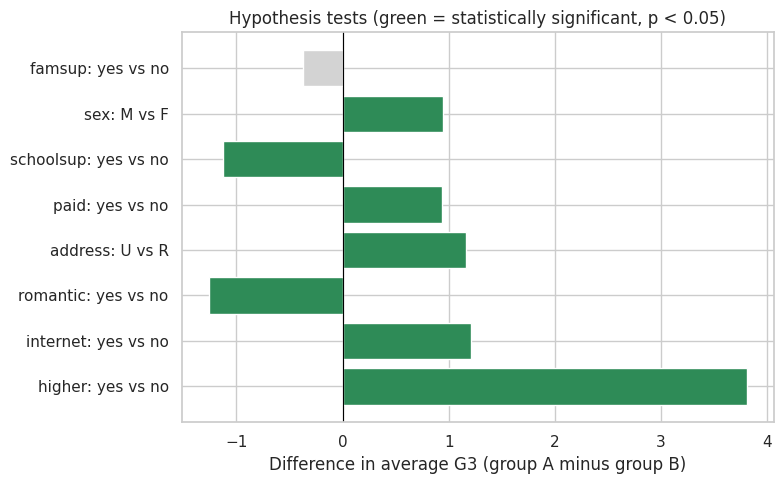

In [9]:
# Cell 8: one summary figure for your report
plot_df = results.copy()
plot_df["label"] = plot_df["feature"] + ": " + plot_df["group A"].str.split(" ").str[0] + " vs " + plot_df["group B"].str.split(" ").str[0]
colors = ["seagreen" if s == "Yes" else "lightgray" for s in plot_df["significant"]]

plt.figure(figsize=(8, 5))
plt.barh(plot_df["label"], plot_df["difference"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Difference in average G3 (group A minus group B)")
plt.title("Hypothesis tests (green = statistically significant, p < 0.05)")
plt.tight_layout()
plt.savefig("hypothesis_tests.png", dpi=150, bbox_inches="tight")
plt.show()